# Concentration paper


In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools
from sonawane_etal import get_data

def set_seed(s):
    import random
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    np.random.seed(s)
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

set_seed(0)

DEVICE = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss1_weight=1, loss2_weight=0.1, patience=0, verbose: bool =True) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.loss1_weight = loss1_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
        self.verbose = verbose
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        # self.Ea = EquationValue(self.n_units, 30000, 70000)
        # self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
        # self.n = EquationValue(self.n_units, 1, 3) 
        self.log_Ea = nn.Parameter(torch.log(torch.tensor(30000, dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_B = nn.Parameter(torch.log(torch.tensor(1e-4,dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_n = nn.Parameter(torch.log(torch.tensor(1.5, dtype=torch.float32, device=DEVICE,requires_grad=True)))
        self.log_rmax = nn.Parameter(torch.log(torch.tensor(8e-9, dtype=torch.float32, device=DEVICE,requires_grad=True)))
        self.log_m = nn.Parameter(torch.log(torch.tensor(1e-5, dtype=torch.float32, device=DEVICE,requires_grad=True)))

    @property
    def Ea(self):
        return torch.exp(self.log_Ea)
    
    @Ea.setter
    def Ea(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_Ea = nn.Parameter(torch.log(value))

    @property
    def B(self):
        return torch.exp(self.log_B)
    
    @B.setter
    def B(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_B = nn.Parameter(torch.log(value))

    @property
    def n(self):
        return torch.exp(self.log_n)

    @n.setter
    def n(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_n = nn.Parameter(torch.log(value))

    @property
    def m(self):
        return torch.exp(self.log_m)

    @m.setter
    def m(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_m = nn.Parameter(torch.log(value))

    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)

        return d
    
    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            # d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            if self.loss2:
                data_loss = self.loss(yt, outputs)
                data_loss = self.loss1_weight * data_loss
                # data_loss = torch.pow(data_loss, 1/0.04)
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
                data_losses.append(data_loss.item())
            else:
                loss = self.loss(yt, outputs)
                loss = self.loss1_weight * loss
                data_losses.append(loss.item())

            loss.backward()

            if torch.isnan(data_loss) or torch.isnan(physic_loss):
                if self.verbose: print("NaN detected in loss. Stopping training.")
                losses = [torch.tensor(np.nan)]
                break

            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    # print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    # print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                    estimateds = f"Ea={self.Ea.item():.2f}, B={self.B.item():.2e}, n={self.n.item():.2f}, m={self.m.item():.2e}"
                else:
                    physic_loss_avg = 0
                    estimateds = ""

                if self.verbose: print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f} - {estimateds}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [3]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

Text(0.5, 0, 'Time (s)')

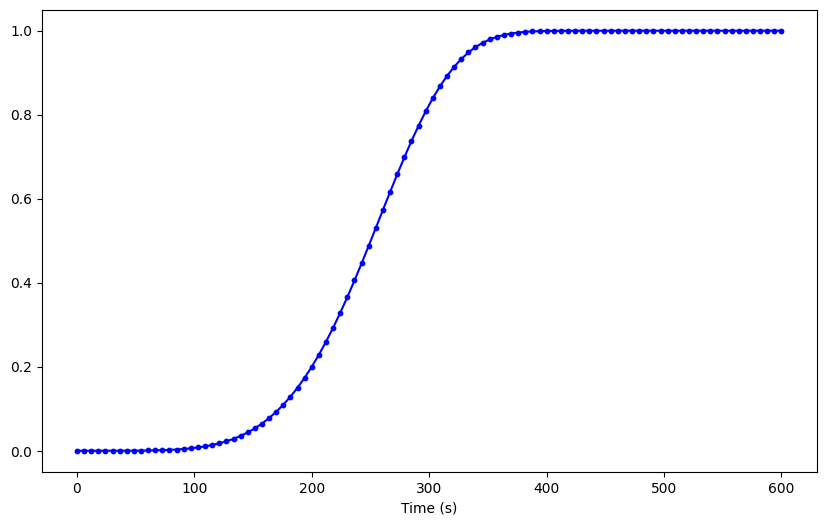

In [4]:
import numpy as np
import functools
import matplotlib.pyplot as plt

# def avrami_law(t,Ea,R,T,A,n,r_max):
#     K = A * np.exp(-Ea / (R * T))
#     d = r_max * (1 - np.exp(-K * t**n))

#     return d

def avrami_law(t,Ea,R,T,B,n,m):
    K = B*np.power(T, m) * np.exp(-Ea / (R * T))
    d = 1 - np.exp(-K * t**n)
    return d

TRAIN_TEMP_CELSIUS = 170

np.random.seed(10)
guessed_B = 1.752e-6              # Increased to speed up transformation
guessed_Ea = 55690            # Lowered to increase reaction rate
T_K = TRAIN_TEMP_CELSIUS + 273.15               # Higher temp for faster growth
r_max = 1 #          # Max radius 
guessed_n = 5.06
R = 8.314
guessed_m = 0.01

TIME_MAX = 600  # seconds

# Time array
times = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, B=guessed_B, m=guessed_m, T=T_K, n=guessed_n, R=R)
values = eq(times)

plt.figure(figsize=(10, 6))
plt.plot(times, values, label='Avrami Law', color='blue')
plt.scatter(times, values, color='blue', s=10)
plt.xlabel('Time (s)')

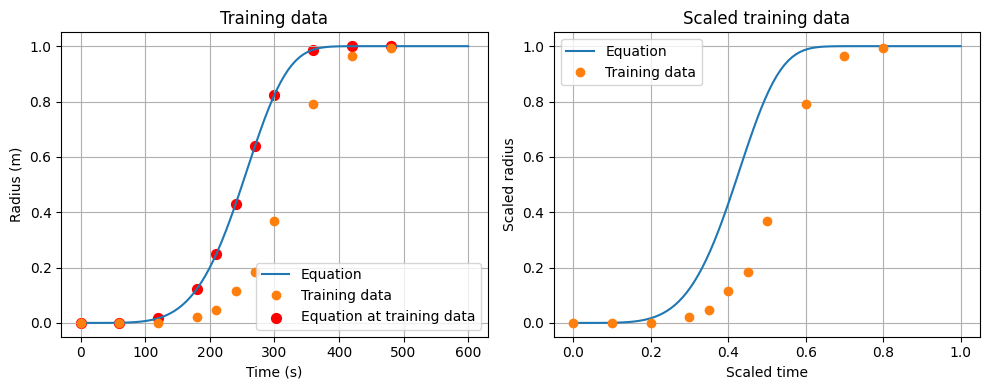

In [5]:

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, B=guessed_B, m=guessed_m, T=T_K, n=guessed_n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9


## Data from concentration paper

all_data = get_data()  # dict[int, dict[str, list[float]]]
data = all_data[TRAIN_TEMP_CELSIUS]  # 170 degree
train_times_X = torch.tensor(data["t"]).reshape(-1, 1) # * 60
train_d_Y = torch.tensor(data["C"]).reshape(-1, 1) # * 1e-9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
plt.scatter(train_times_X, eq(train_times_X), color='red', s=50, label="Equation at training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

/tmp/ipykernel_567201/1863473018.py:17: RuntimeWarning: overflow encountered in power
  K = B * np.power(T, m) * np.exp(-np.clip(Ea / (R * T), -700, 700))
/tmp/ipykernel_567201/1863473018.py:18: RuntimeWarning: overflow encountered in power
  return 1 - np.exp(-np.clip(K * t**n, -700, 700))
/tmp/ipykernel_567201/1863473018.py:18: RuntimeWarning: invalid value encountered in multiply
  return 1 - np.exp(-np.clip(K * t**n, -700, 700))


=== curve_fit (LM) ===
Ea (J/mol): 6.297e+04 ± 1.127e+10
   B (m/s): 2.901e-09 ± 0.008699
         n: 6.383 ± 0.6647
         m: -0.07681 ± 1.384e+05
       R^2: 0.9941

=== curve_fit (trf) ===
Ea (J/mol): 6.297e+04 ± 0.000148
   B (m/s): 2.901e-09 ± 1.329e-07
         n: 6.383 ± 2.558
         m: -0.07681 ± 3.322
       R^2: 0.9811

=== differential_evolution ===
Ea (J/mol): 9.852e+04
   B (m/s): 8.248e-06
         n: 6.384
         m: 0.2002
       R^2: 0.9941



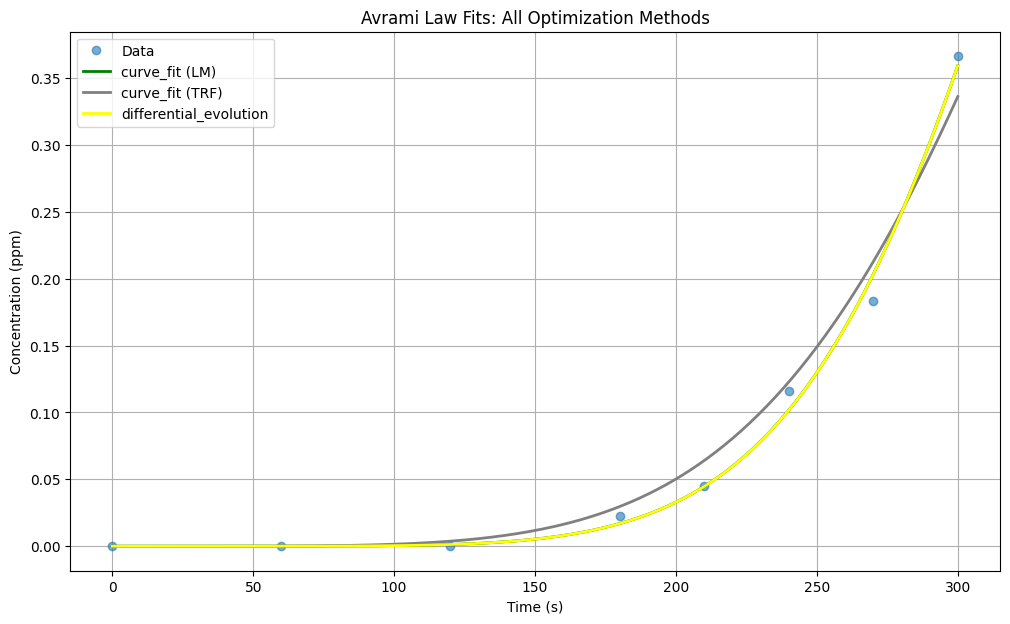

Best fit parameters (curve_fit):
B: 2.901e-09 ± 0.008699
Ea: 6.297e+04 ± 1.127e+10
n: 6.383 ± 0.6647
m: -0.07681 ± 1.384e+05


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize, differential_evolution

# --- Prepare data ------------------------------------------------------------
times = train_times_X.flatten().numpy()
X     = train_d_Y.flatten().numpy()

# Limit to 8 datapoints
times = times[:8]
X = X[:8]

R = 8.314  # J/(mol·K)

def avrami_law(t, Ea, R, T, B, n, m):
    t = np.clip(t, 1e-6, None)  # Avoid 0^n
    K = B * np.power(T, m) * np.exp(-np.clip(Ea / (R * T), -700, 700))
    return 1 - np.exp(-np.clip(K * t**n, -700, 700))

def model(t, Ea, B, n, m):
    return avrami_law(t, Ea, R, T_K, B, n, m)

def residuals(params, t, y):
    return y - model(t, *params)

def ssq(params, t, y):
    res = residuals(params, t, y)
    return np.dot(res, res)

guessed_Ea_1 = 50000  # example, in J/mol
guessed_B_1 = 1e-6    # example
guessed_n_1 = 2.0     # example
guessed_m_1 = 0.5     # example
initial_guess = np.asarray([guessed_Ea_1, guessed_B_1, guessed_n_1, guessed_m_1])

bounds = [(10000, 1e5), (1e-10, 1e-3), (1, 10), (1e-2, 1)]

# --- Optimizations -----------------------------------------------------------
popt_cf, pcov_cf = curve_fit(model, times, X, p0=initial_guess, method='lm')
perr_cf = np.sqrt(np.diag(pcov_cf))

popt_cf1, pcov_cf1 = curve_fit(model, times, X, p0=initial_guess,bounds=tuple(zip(*bounds)),method='trf')
perr_cf1 = np.sqrt(np.diag(pcov_cf1))

res_min = minimize(ssq, x0=initial_guess, args=(times, X), method='BFGS', options={'disp': False})
popt_min = res_min.x
cov_min = res_min.hess_inv
perr_min = np.sqrt(np.diag(cov_min))

# --- Global methods ----------------------------------------------------------
result_de = differential_evolution(lambda p: ssq(p, times, X), bounds)
popt_de = result_de.x

# --- R² Calculation ----------------------------------------------------------
def r_squared(y_true, y_pred):
    if np.any(np.isnan(y_pred)):
        return np.nan
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

r2_cf  = r_squared(X, model(times, *popt_cf))
r2_cf1  = r_squared(X, model(times, *popt_cf1))
r2_cf2  = r_squared(X, model(times, *popt_cf2))
r2_min = r_squared(X, model(times, *popt_min))
r2_de  = r_squared(X, model(times, *popt_de))

# --- Print Results -----------------------------------------------------------
names = ['Ea (J/mol)', 'B (m/s)', 'n', 'm']

def print_result(method, popt, perr=None, r2=None):
    print(f"=== {method} ===")
    for i, name in enumerate(names):
        if perr is not None:
            print(f"{name:>10s}: {popt[i]:.4g} ± {perr[i]:.4g}")
        else:
            print(f"{name:>10s}: {popt[i]:.4g}")
    if r2 is not None:
        print(f"{'R^2':>10s}: {r2:.4f}")
    print()

print_result("curve_fit (LM)", popt_cf, perr_cf, r2_cf)
print_result("curve_fit (trf)", popt_cf, perr_cf1, r2_cf1)
#print_result("curve_fit (dogbox)", popt_cf, perr_cf2, r2_cf2)
#print_result("minimize (BFGS)", popt_min, perr_min, r2_min)
print_result("differential_evolution", popt_de, r2=r2_de)
#print_result("dual_annealing", popt_da, r2=r2_da)

# --- Plot Results ------------------------------------------------------------
plt.figure(figsize=(12, 7))
plt.plot(times, X, 'o', label='Data', alpha=0.6)
t_plot = np.linspace(times.min(), times.max(), 200)

plt.plot(t_plot, model(t_plot, *popt_cf), label='curve_fit (LM)', color ='green', lw=2)
plt.plot(t_plot, model(t_plot, *popt_cf1), label='curve_fit (TRF)', color ='grey', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_cf2), label='curve_fit (DOGBOX)', color ='yellow', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_min), label='minimize (L-BFGS)', color='red', lw=2)
plt.plot(t_plot, model(t_plot, *popt_de), label='differential_evolution', color='yellow', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_da), label='dual_annealing',color ='blue', lw=2)

plt.xlabel('Time (s)')
plt.ylabel('Concentration (ppm)')
plt.title('Avrami Law Fits: All Optimization Methods')
plt.legend()
plt.grid(True)
plt.show()

# --- Best Fit Parameters (curve_fit) -----------------------------------------
print("Best fit parameters (curve_fit):")
print(f"B: {popt_cf[1]:.4g} ± {perr_cf[1]:.4g}")
print(f"Ea: {popt_cf[0]:.4g} ± {perr_cf[0]:.4g}")
print(f"n: {popt_cf[2]:.4g} ± {perr_cf[2]:.4g}")
print(f"m: {popt_cf[3]:.4g} ± {perr_cf[3]:.4g}")




In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize, differential_evolution

# --- Prepare data ------------------------------------------------------------
times = train_times_X.flatten().numpy()
X     = train_d_Y.flatten().numpy()

times = times[:4]
X = X[:4]

R = 8.314  # J/(mol·K)

def avrami_law(t, Ea, R, T, B, n, m):
    t = np.clip(t, 1e-6, None)  # Avoid 0^n
    K = B * np.power(T, m) * np.exp(-np.clip(Ea / (R * T), -700, 700))
    return 1 - np.exp(-np.clip(K * t**n, -700, 700))

def model(t, Ea, B, n, m):
    return avrami_law(t, Ea, R, T_K, B, n, m)

def residuals(params, t, y):
    return y - model(t, *params)

def ssq(params, t, y):
    res = residuals(params, t, y)
    return np.dot(res, res)

guessed_Ea_1 = 50000  # example, in J/mol
guessed_B_1 = 1e-6    # example
guessed_n_1 = 2.0     # example
guessed_m_1 = 0.5     # example
initial_guess = np.asarray([guessed_Ea_1, guessed_B_1, guessed_n_1, guessed_m_1])

bounds = [(10000, 1e5), (1e-10, 1e-3), (1, 10), (1e-2, 1)]

# --- Optimizations -----------------------------------------------------------
popt_cf, pcov_cf = curve_fit(model, times, X, p0=initial_guess, method='lm')
perr_cf = np.sqrt(np.diag(pcov_cf))

popt_cf1, pcov_cf1 = curve_fit(model, times, X, p0=initial_guess,bounds=tuple(zip(*bounds)),method='trf')
perr_cf1 = np.sqrt(np.diag(pcov_cf1))

popt_cf2, pcov_cf2 = curve_fit(model, times, X, p0=initial_guess, method='dogbox')
perr_cf2 = np.sqrt(np.diag(pcov_cf2))

res_min = minimize(ssq, x0=initial_guess, args=(times, X), method='BFGS', options={'disp': False})
popt_min = res_min.x
cov_min = res_min.hess_inv
perr_min = np.sqrt(np.diag(cov_min))

# --- Global methods ----------------------------------------------------------
result_de = differential_evolution(lambda p: ssq(p, times, X), bounds)
popt_de = result_de.x

# --- R² Calculation ----------------------------------------------------------
def r_squared(y_true, y_pred):
    if np.any(np.isnan(y_pred)):
        return np.nan
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

r2_cf  = r_squared(X, model(times, *popt_cf))
r2_cf1  = r_squared(X, model(times, *popt_cf1))
r2_cf2  = r_squared(X, model(times, *popt_cf2))
r2_min = r_squared(X, model(times, *popt_min))
r2_de  = r_squared(X, model(times, *popt_de))

# --- Print Results -----------------------------------------------------------
names = ['Ea (J/mol)', 'B (m/s)', 'n', 'm']

def print_result(method, popt, perr=None, r2=None):
    print(f"=== {method} ===")
    for i, name in enumerate(names):
        if perr is not None:
            print(f"{name:>10s}: {popt[i]:.4g} ± {perr[i]:.4g}")
        else:
            print(f"{name:>10s}: {popt[i]:.4g}")
    if r2 is not None:
        print(f"{'R^2':>10s}: {r2:.4f}")
    print()

print_result("curve_fit (LM)", popt_cf, perr_cf, r2_cf)
print_result("curve_fit (trf)", popt_cf, perr_cf1, r2_cf1)
#print_result("curve_fit (dogbox)", popt_cf, perr_cf2, r2_cf2)
#print_result("minimize (BFGS)", popt_min, perr_min, r2_min)
print_result("differential_evolution", popt_de, r2=r2_de)
#print_result("dual_annealing", popt_da, r2=r2_da)

# --- Plot Results ------------------------------------------------------------
plt.figure(figsize=(12, 7))
plt.plot(times, X, 'o', label='Data', alpha=0.6)
t_plot = np.linspace(times.min(), times.max(), 200)

plt.plot(t_plot, model(t_plot, *popt_cf), label='curve_fit (LM)', color ='green', lw=2)
plt.plot(t_plot, model(t_plot, *popt_cf1), label='curve_fit (TRF)', color ='grey', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_cf2), label='curve_fit (DOGBOX)', color ='yellow', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_min), label='minimize (L-BFGS)', color='red', lw=2)
plt.plot(t_plot, model(t_plot, *popt_de), label='differential_evolution', color='yellow', lw=2)
#plt.plot(t_plot, model(t_plot, *popt_da), label='dual_annealing',color ='blue', lw=2)

plt.xlabel('Time (s)')
plt.ylabel('Concentration (ppm)')
plt.title('Avrami Law Fits: All Optimization Methods')
plt.legend()
plt.grid(True)
plt.show()

# --- Best Fit Parameters (curve_fit) -----------------------------------------
print("Best fit parameters (curve_fit):")
print(f"B: {popt_cf[1]:.4g} ± {perr_cf[1]:.4g}")
print(f"Ea: {popt_cf[0]:.4g} ± {perr_cf[0]:.4g}")
print(f"n: {popt_cf[2]:.4g} ± {perr_cf[2]:.4g}")
print(f"m: {popt_cf[3]:.4g} ± {perr_cf[3]:.4g}")




/tmp/ipykernel_567201/1303574341.py:16: RuntimeWarning: overflow encountered in power
  K = B * np.power(T, m) * np.exp(-np.clip(Ea / (R * T), -700, 700))
/tmp/ipykernel_567201/1303574341.py:17: RuntimeWarning: overflow encountered in power
  return 1 - np.exp(-np.clip(K * t**n, -700, 700))
/tmp/ipykernel_567201/1303574341.py:17: RuntimeWarning: invalid value encountered in multiply
  return 1 - np.exp(-np.clip(K * t**n, -700, 700))


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 1000.

=== curve_fit ===
Ea (J/mol): 5.569e+04 ± 6.545e-05
   B (m/s): 8.133e-08 ± 2.483e-07
         n: 5.277 ± 1.094
         m: 0.103 ± 1.47
       R^2: 0.9933

=== minimize (BFGS) ===
Ea (J/mol): 5.569e+04 ± 1
   B (m/s): 1.752e-06 ± 1
         n: 5.06 ± 1
         m: 0.01 ± 1
       R^2: 0.6263

=== least_squares (LM) ===
Ea (J/mol): 5.569e+04 ± nan
   B (m/s): 6.13e-11 ± nan
         n: 6.625 ± nan
         m: 0.009522 ± nan
       R^2: 0.9991


/tmp/ipykernel_519631/549426560.py:13: RuntimeWarning: overflow encountered in exp
  d = 1 - np.exp(-K * t**n)
/home/usyed/miniconda3/envs/ChemReact/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0
/tmp/ipykernel_519631/549426560.py:13: RuntimeWarning: overflow encountered in exp
  d = 1 - np.exp(-K * t**n)
/tmp/ipykernel_519631/549426560.py:13: RuntimeWarning: overflow encountered in exp
  d = 1 - np.exp(-K * t**n)


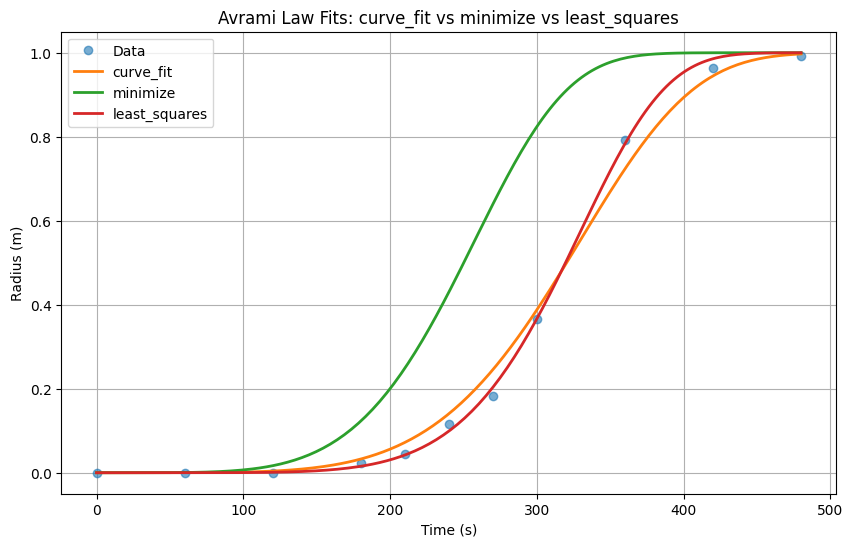

Best fit parameters:
B: 8.133e-08 ± 2.483e-07
Ea: 5.569e+04 ± 6.545e-05
n: 5.277 ± 1.094
m: 0.103 ± 1.47


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize, least_squares

# --- Prepare data ------------------------------------------------------------
# flatten & convert from PyTorch tensors
times = train_times_X.flatten().numpy()
X     = train_d_Y.flatten().numpy()

# constants
R = 8.314  # J/(mol·K)

# Avrami-law model wrapper for all optimizers
def model(t, Ea, B, n, m):
    return avrami_law(t=t, Ea=Ea, R=R, T=T_K, B=B, n=n, m=m)

# residual vector for least_squares/minimize
def residuals(params, t, y):
    return y - model(t, *params)

# scalar objective for minimize: sum of squared residuals
def ssq(params, t, y):
    res = residuals(params, t, y)
    return np.dot(res, res)


# initial guesses
initial_guess = np.asarray([guessed_Ea, guessed_B, guessed_n, guessed_m])


# 1) curve_fit ----------------------------------------------------------------
popt_cf, pcov_cf = curve_fit(model, times, X, p0=initial_guess, method='trf')
perr_cf = np.sqrt(np.diag(pcov_cf))


# 2) minimize (BFGS) -----------------------------------------------------------
res_min = minimize(ssq,
                   x0=initial_guess,
                   args=(times, X),
                   method='BFGS',
                   options={'disp': False})
popt_min = res_min.x

# invert Hessian approx. for parameter variances
# for BFGS, hess_inv is an ndarray
cov_min = res_min.hess_inv
perr_min = np.sqrt(np.diag(cov_min))


# 3) least_squares -------------------------------------------------------------
res_ls = least_squares(residuals,
                       x0=initial_guess,
                       args=(times, X),
                       method='lm')
popt_ls = res_ls.x

# covariance from Jacobian
J = res_ls.jac
cov_ls = np.linalg.inv(J.T.dot(J))
perr_ls = np.sqrt(np.diag(cov_ls))


# # --- Print results ----------------------------------------------------------
# names = ['Ea (J/mol)', 'B (m/s)', 'n', 'm']
# print("=== curve_fit ===")
# for name, val, err in zip(names, popt_cf, perr_cf):
#     print(f"{name:>10s}: {val:.4g} ± {err:.4g}")

# print("\n=== minimize (BFGS) ===")
# for name, val, err in zip(names, popt_min, perr_min):
#     print(f"{name:>10s}: {val:.4g} ± {err:.4g}")

# print("\n=== least_squares (LM) ===")
# for name, val, err in zip(names, popt_ls, perr_ls):
#     print(f"{name:>10s}: {val:.4g} ± {err:.4g}")

# --- Compute R^2 values -----------------------------------------------------
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

r2_cf  = r_squared(X, model(times, *popt_cf))
r2_min = r_squared(X, model(times, *popt_min))
r2_ls  = r_squared(X, model(times, *popt_ls))


# --- Print results ----------------------------------------------------------
names = ['Ea (J/mol)', 'B (m/s)', 'n', 'm']
print("=== curve_fit ===")
for name, val, err in zip(names, popt_cf, perr_cf):
    print(f"{name:>10s}: {val:.4g} ± {err:.4g}")
print(f"{'R^2':>10s}: {r2_cf:.4f}")

print("\n=== minimize (BFGS) ===")
for name, val, err in zip(names, popt_min, perr_min):
    print(f"{name:>10s}: {val:.4g} ± {err:.4g}")
print(f"{'R^2':>10s}: {r2_min:.4f}")

print("\n=== least_squares (LM) ===")
for name, val, err in zip(names, popt_ls, perr_ls):
    print(f"{name:>10s}: {val:.4g} ± {err:.4g}")
print(f"{'R^2':>10s}: {r2_ls:.4f}")

# --- Plot comparison --------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.plot(times, X, 'o', label='Data', alpha=0.6)

t_plot = np.linspace(times.min(), times.max(), 200)
plt.plot(t_plot, model(t_plot, *popt_cf), label='curve_fit',    lw=2)
plt.plot(t_plot, model(t_plot, *popt_min), label='minimize',     lw=2) # , linestyle='--')
plt.plot(t_plot, model(t_plot, *popt_ls), label='least_squares', lw=2) # , linestyle=':')

# plt.plot(gt_times_X, gt_d_Y, 'k-.', label='True Model')

plt.xlabel('Time (s)')
plt.ylabel('Radius (m)')
plt.title('Avrami Law Fits: curve_fit vs minimize vs least_squares')
plt.legend()
plt.grid(True)
plt.show()

# use curve fit as comparison
B_opt = popt_cf[1]
Ea_opt = popt_cf[0]
n_opt = popt_cf[2]
m_opt = popt_cf[3]

print("Best fit parameters:")
print(f"B: {B_opt:.4g} ± {perr_cf[1]:.4g}")
print(f"Ea: {Ea_opt:.4g} ± {perr_cf[0]:.4g}")
print(f"n: {n_opt:.4g} ± {perr_cf[2]:.4g}")
print(f"m: {m_opt:.4g} ± {perr_cf[3]:.4g}")

In [12]:
import os


vannilla_pretrained = "vanilla_pretrained_concentration_mod.pth"
vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
retrain = True
if os.path.exists(vannilla_pretrained):
    try:
        vanilla.load_state_dict(torch.load(vannilla_pretrained))
        print("Loaded pretrained model")
        retrain = False
    except Exception as e:
        print("Error loading pretrained model, retraining" , e)    

if retrain:
    losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
    plt.plot(losses)
    plt.yscale('log')
    torch.save(vanilla.state_dict(), vannilla_pretrained)


UnboundLocalError: cannot access local variable 'data_loss' where it is not associated with a value

Epoch 0/100000, loss: 1.233618 - data_loss: 1.224153 - physic_loss: 0.009465 - Ea=30002.99, B=6.51e-08, n=2.50, m=8.24e-02
Epoch 10000/100000, loss: 0.046337 - data_loss: 0.020793 - physic_loss: 0.025543 - Ea=32998.95, B=6.18e-08, n=4.31, m=8.14e-02
Epoch 20000/100000, loss: 0.033593 - data_loss: 0.010807 - physic_loss: 0.022787 - Ea=67518.84, B=3.17e-08, n=6.08, m=4.38e-02
Epoch 30000/100000, loss: 0.028421 - data_loss: 0.007420 - physic_loss: 0.021001 - Ea=73434.93, B=2.92e-08, n=6.37, m=4.04e-02
Epoch 40000/100000, loss: 0.025466 - data_loss: 0.005734 - physic_loss: 0.019732 - Ea=74538.59, B=2.88e-08, n=6.42, m=3.98e-02
Epoch 50000/100000, loss: 0.023626 - data_loss: 0.004724 - physic_loss: 0.018901 - Ea=75198.91, B=2.85e-08, n=6.45, m=3.94e-02
Epoch 60000/100000, loss: 0.022330 - data_loss: 0.004055 - physic_loss: 0.018275 - Ea=75542.27, B=2.84e-08, n=6.46, m=3.92e-02
Epoch 70000/100000, loss: 0.021390 - data_loss: 0.003576 - physic_loss: 0.017814 - Ea=75776.41, B=2.83e-08, n=6.48,

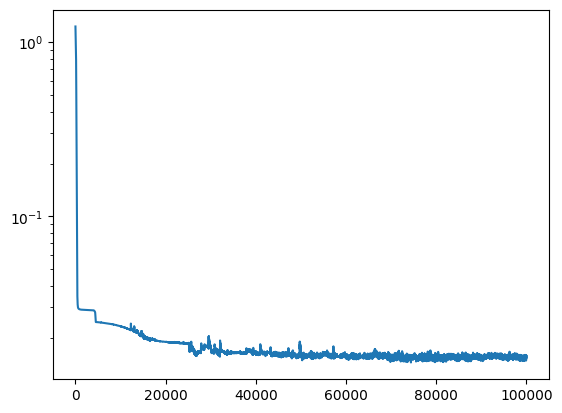

In [ ]:
import torch.nn.functional as F


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def positive_activation(x, offset=1e-6):
    # First apply softplus, then a bias offset, then optionally exponentiate for sharper contrast
    return torch.exp(F.softplus(x)) + offset

T_tensor = torch.tensor(T_K, dtype=torch.float32, device=DEVICE, requires_grad=True)
ts = torch.linspace(0, TIME_MAX, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    # d, Ea_net, A_net, n_net = out[:, 0], out[:, 1], out[:, 2], out[:, 3]  # [-1, 1] [0, 1]
    d = out
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = model.Ea
    B =  model.B
    n =  model.n
    m = model.m

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = B * T_tensor.pow(m) * torch.exp(-Ea / (R * T_tensor))    
    # Compute the derivative of d(t) with respect to t
    derived_eq = K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10

        # PROBLEM: when 1/exponent is too small, loss is too "flat" and less sensitive to gradient descent
        # alpha = 1/abs(exponent)  # computed as before
        # delta = 0.1  # adjust this value as needed
        # alpha_eff = min(alpha + delta, 1.0)
        # # regularized_loss = scaled_loss ** alpha_eff
        # PHYSICAL_LOSS_SCALING_FACTOR = alpha_eff
    
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)
    # physical_loss = torch.nn.functional.softplus(physical_loss)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# {'loss1_weight': 6.514892186917204, 'loss2_weight': 0.7595986531199583, 'lr': 0.004407993997106438
# Best hyperparameters:  {'loss1_weight': 6.561174668973715, 'loss2_weight': 0.08277899753305118}

# net = DiscoveryNet(1, 3, loss1_weight=6.5, loss2=physics_loss, loss2_weight=0.75, epochs=100000, lr=0.0044).to(DEVICE)
net = DiscoveryNet(1, 3, loss1_weight=6.5611, loss2=physics_loss, loss2_weight=0.08277, epochs=100000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss1_weight=1, loss2=physics_loss, loss2_weight=0.01, epochs=100000, lr=1e-4).to(DEVICE)

net.B = B_opt - (B_opt * 0.2)
net.Ea = 30000 # Ea_opt - (Ea_opt * 0.2)
net.n = 2.5 # n_opt - (n_opt * 0.2)
net.m = m_opt - (m_opt * 0.2)

losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

In [ ]:
def r2_score(y_true: torch.Tensor,
             y_pred: torch.Tensor,
             eps: float = 1e-10) -> torch.Tensor:
    """
    Compute the coefficient of determination, R^2, between y_true and y_pred.

    R^2 = 1 - SS_res / SS_tot
    where
      SS_res = sum((y_true - y_pred)^2)
      SS_tot = sum((y_true - y_true_mean)^2)

    Args:
        y_true (torch.Tensor): Ground-truth targets.
        y_pred (torch.Tensor): Model predictions.
        eps (float): Small value to avoid division by zero.

    Returns:
        torch.Tensor: Scalar tensor with the R^2 value.
    """
    
    if not isinstance(y_true, torch.Tensor):
        y_true = torch.as_tensor(y_true, dtype=torch.float32)
    if not isinstance(y_pred, torch.Tensor):
        y_pred = torch.as_tensor(y_pred, dtype=torch.float32)
    
    y_true = y_true.cpu()
    y_pred = y_pred.cpu()

    # Flatten in case of multi-dim input
    y_true = y_true.view(-1)
    y_pred = y_pred.view(-1)

    # Sum of squares of residuals
    ss_res = torch.sum((y_true - y_pred) ** 2)

    # Total sum of squares
    y_mean = torch.mean(y_true)
    ss_tot = torch.sum((y_true - y_mean) ** 2)

    # R^2
    r2 = 1 - ss_res / (ss_tot + eps)
    return r2

# calculate R^2 over training data
net.eval()
train_d_Y_pred = net.predict(curr_train_times_X)
train_d_Y_pred = scaler_Y.inverse_transform(torch.as_tensor(train_d_Y_pred, dtype=torch.float32, device=DEVICE))
train_d_Y = scaler_Y.inverse_transform(curr_train_d_Y)
train_d_Y = train_d_Y.cpu().numpy()
train_d_Y_pred = train_d_Y_pred.cpu().numpy()
# r2 = 1 - (np.sum((train_d_Y - train_d_Y_pred) ** 2) / np.sum((train_d_Y - np.mean(train_d_Y)) ** 2))
r2 = r2_score(train_d_Y, train_d_Y_pred)

# calculate R^2 over equation data
eq_pred = functools.partial(avrami_law, Ea=net.Ea.item(), B=net.B.item(), m=net.m.item(), T=T_K, n=net.n.item(), R=R)
eq_d_Y = eq_pred(train_times_X.cpu().numpy())
r2_eq = r2_score(train_d_Y, eq_d_Y)

print(f"R^2 (data): {r2:.6f}")
print(f"R^2 (equation): {r2_eq:.6f}")
print("--" * 10)
print("Ea:", net.Ea.item())
print("n:", net.n.item())
print("B:", net.B.item())
print("m:", net.m.item())

# print(positive_activation(net.Ea).item(), positive_activation(net.A).item(), positive_activation(net.n).item())

R^2 (data): 0.999273
R^2 (equation): 0.999089
--------------------
Ea: 76007.2890625
n: 6.4871506690979
B: 2.8213404945631737e-08
m: 0.03899151459336281


In [ ]:
if False:
    # optuna optimizations of weights as grid search
    import optuna
    
    def objective(trial):
        # Define the hyperparameters to tune
        loss1_weight = trial.suggest_float("loss1_weight", 0.01, 10.0)
        loss2_weight = trial.suggest_float("loss2_weight", 0.01, 10.0)
        # epochs = trial.suggest_int("epochs", 10000, 200000)
        lr = trial.suggest_float("lr", 1e-5, 1e-2)
        # lr = 1e-4

        # Create a new instance of the model with the current hyperparameters
        model = DiscoveryNet(1, 3, loss1_weight=loss1_weight, loss2=physics_loss, loss2_weight=loss2_weight, epochs=20000, lr=lr, verbose=False).to(DEVICE)
        model.B = B_opt - (B_opt * 0.2)
        model.Ea = 30000 # Ea_opt - (Ea_opt * 0.2)
        model.n = 2.5 # n_opt - (n_opt * 0.2)
        model.m = m_opt - (m_opt * 0.2)

        # Train the model
        losses = model.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

        if any([torch.isnan(torch.as_tensor(l)) for l in losses]):
            return torch.tensor(np.nan)

        # Calculate R^2 over training data
        model.eval()
        train_d_Y_pred = model.predict(curr_train_times_X)
        train_d_Y_pred = scaler_Y.inverse_transform(torch.as_tensor(train_d_Y_pred, dtype=torch.float32, device=DEVICE))
        train_d_Y = scaler_Y.inverse_transform(curr_train_d_Y)
        train_d_Y = train_d_Y.cpu().numpy()
        train_d_Y_pred = train_d_Y_pred.cpu().numpy()
        # r2 = 1 - (np.sum((train_d_Y - train_d_Y_pred) ** 2) / np.sum((train_d_Y - np.mean(train_d_Y)) ** 2))
        r2 = r2_score(train_d_Y, train_d_Y_pred)

        # compute R^2 over equation data
        eq_pred = functools.partial(avrami_law, Ea=model.Ea.item(), B=model.B.item(), m=model.m.item(), T=T_K, n=model.n.item(), R=R)
        train_times_unscaled = scaler_X.inverse_transform(curr_train_times_X)
        train_times_unscaled = train_times_unscaled.cpu().numpy()
        eq_d_pred = eq_pred(train_times_X)

        # plt.plot(train_times_unscaled, train_d_Y, 'o', label="Training data")
        # plt.plot(train_times_unscaled, train_d_Y_pred, 'o', label="Model prediction")
        # plt.plot(train_times_unscaled, eq_pred(train_times_unscaled), 'o', label="Equation prediction")
        # plt.xlabel("Time (s)")
        # plt.ylabel("Radius (m)")
        # plt.title("Training data")
        # plt.legend()
        # plt.show(block=False)

        # r2_eq = 1 - (np.sum((eq_d_Y - train_d_Y) ** 2) / np.sum((eq_d_Y - np.mean(eq_d_Y)) ** 2))
        r2_score_eq = r2_score(train_d_Y, eq_d_pred)

        # Combine the two R^2 values into a single score
        r2 = (r2 + r2_score_eq) / 2
        # Print the hyperparameters and the corresponding R^2 score
        print(f"Trial {trial.number}: loss1_weight={loss1_weight:.4f}, loss2_weight={loss2_weight:.4f}, lr={lr:.4e} => R^2={r2:.4f}")

        return r2

    # Create a study object
    study = optuna.create_study(direction="maximize")
    # Optimize the objective function
    study.optimize(objective, n_trials=150, n_jobs=-1, timeout=600)
    # Print the best hyperparameters
    print("Best hyperparameters: ", study.best_params)
    print("Best R^2: ", study.best_value)
    # Save the study
    import joblib
    joblib.dump(study, "study.pkl")
    

Predicted B: 2.8213e-08, Guess B: 8.1331e-08  -  difference: -5.3117e-08
Predicted Ea: 76007.29, Guess Ea: 55690.00  -  difference: 20317.29
Predicted n: 6.4872, Guess n: 5.2773  -  difference: 1.21
Predicted m: 3.8992e-02, Guess m: 3.8992e-02  -  difference: -6.40e-02
R^2 (train data): 0.999273
R^2 (equation data): 0.999089


/tmp/ipykernel_2152096/2318104594.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = 1 - np.exp(-K * t**n)


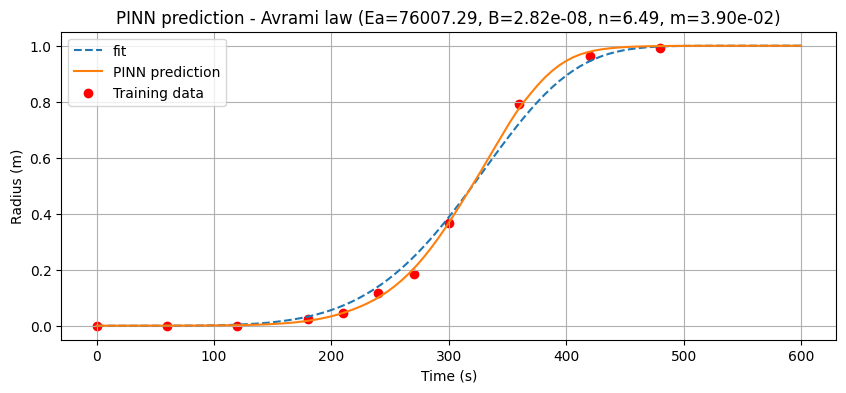

In [ ]:
# plot the prediction on gt data

d = net.predict(eq_times_X_scaled)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = net.Ea.item()
A_net = net.B.item()
n_net = net.n.item()
m_net = net.m.item()

# expected:
Ea = Ea_net
B = A_net
n = n_net
m = m_net

# Ea_opt, A_opt, n_opt
B_expected = B_opt
Ea_expected = Ea_opt
n_expected = n_opt
m_expected = m_opt
# r_max_expected = r_max_opt = r_max

print(f"Predicted B: {B:.4e}, Guess B: {B_expected:.4e}  -  difference: {(B - B_expected):.4e}")
print(f"Predicted Ea: {Ea:.2f}, Guess Ea: {Ea_expected:.2f}  -  difference: {(Ea - Ea_expected):.2f}")
print(f"Predicted n: {n_net:.4f}, Guess n: {n_expected:.4f}  -  difference: {(n - n_expected):.2f}")
print(f"Predicted m: {m_net:.4e}, Guess m: {m:.4e}  -  difference: {(m_net - m_expected):.2e}")

# calculate R^2 over training data
train_d_Y_pred = net.predict(curr_train_times_X)
train_d_Y_pred = scaler_Y.inverse_transform(torch.as_tensor(train_d_Y_pred, dtype=torch.float32, device=DEVICE))
train_d_Y = scaler_Y.inverse_transform(curr_train_d_Y)
train_d_Y = train_d_Y.cpu().numpy()
train_d_Y_pred = train_d_Y_pred.cpu().numpy()
r2 = r2_score(train_d_Y, train_d_Y_pred)
print(f"R^2 (train data): {r2:.6f}")

# calculate R^2 over equation data
eq_pred = functools.partial(avrami_law, Ea=Ea, B=B, m=m, T=T_K, n=n, R=R)
eq_d_pred = eq_pred(train_times_X)
r2_eq = r2_score(train_d_Y, eq_d_pred)
print(f"R^2 (equation data): {r2_eq:.6f}")

# print(f"Predicted r_max: {r_max:.2e}, Guess r_max: {r_max_expected:.2e}  -  abs difference: {abs(r_max - r_max_expected):.2e}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)

eq_fitted_opt = functools.partial(avrami_law, B=B_opt, Ea=Ea_opt, T=T_K, n=n_opt, m=m_opt, R=R)
plt.plot(gt_times_X, eq_fitted_opt(gt_times_X), label="fit", linestyle='--')
plt.plot(gt_times_X, d, label="PINN prediction")
# plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
# plot train data
plt.scatter(train_times_X, train_d_Y , marker='o', label="Training data", color="red")
# plt.scatter(train_times_X, eq_pred(train_times_X), marker="x", s=50, label="Equation at training data", color="brown")

plt.title(f"PINN prediction - Avrami law (Ea={Ea:.2f}, B={B:.2e}, n={n:.2f}, m={m:.2e})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()


# # plot all Ea and A values
# plt.figure(figsize=(10, 4))
# plt.subplot(1, 3, 1)
# plt.plot(gt_times_X, Ea, label="Ea")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 2)
# plt.plot(gt_times_X, A, label="A")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 3)
# plt.plot(gt_times_X, n, label="n")
# plt.legend()
# plt.grid()
# plt.show()


# plt.figure(figsize=(10, 4))
# # plot avrami eq using predicted A and Ea
# times = torch.linspace(200, 600, 100)
# # times = torch.linspace(350, 400, 100)
# # times = torch.linspace(0, TIME_MAX, 100)

# times_s = scaler_X.transform(times.reshape(-1, 1)).type(torch.float32).to(DEVICE)
# times_s = times_s.reshape(-1, 1)
# d = net.predict(times_s)
# d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
# d = scaler_Y.inverse_transform(d)
# d = d.cpu().numpy()
# plt.plot(times.cpu().numpy(), d, label="PINN prediction")

# eq_temp = functools.partial(avrami_law, B=B, Ea=Ea, T=T, n=n, m=m, R=R)
# eq_d_Y = eq_temp(times)
# plt.plot(times, eq_d_Y, label=f"Ea={Ea:.2f}, B={B:.2e}, n={n:.2f} rmax={r_max:.2e}", color='red')
# plt.scatter(times.cpu().numpy(), eq_d_Y, color='red', s=10)
# plt.legend()
# plt.grid()
# plt.show()

Using predicted values of Ea=76007.29, A=2.8213e-08, n=6.49, m=3.8992e-02


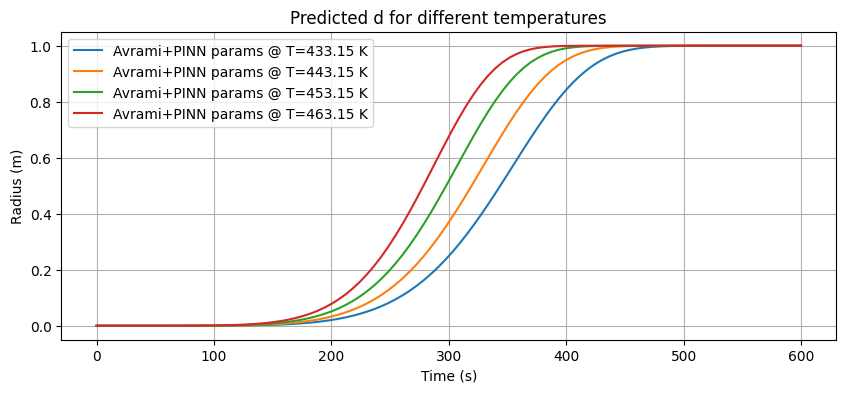

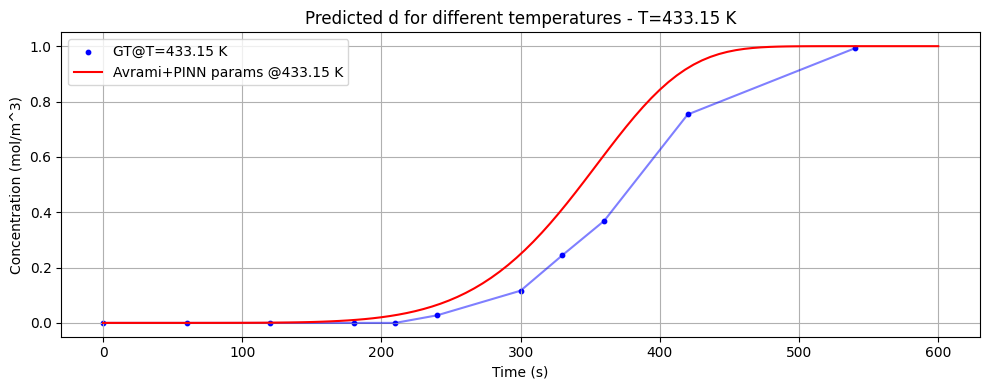

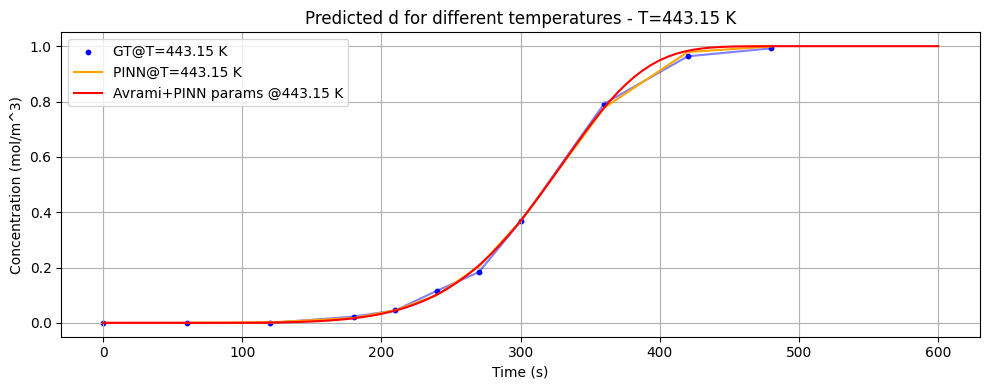

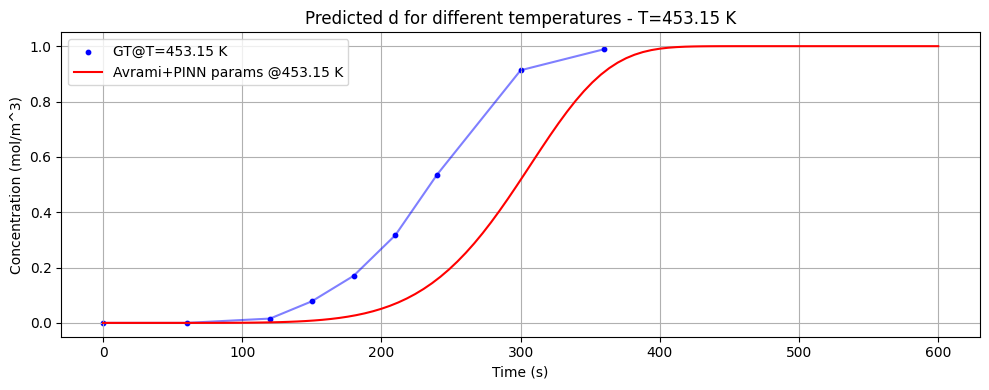

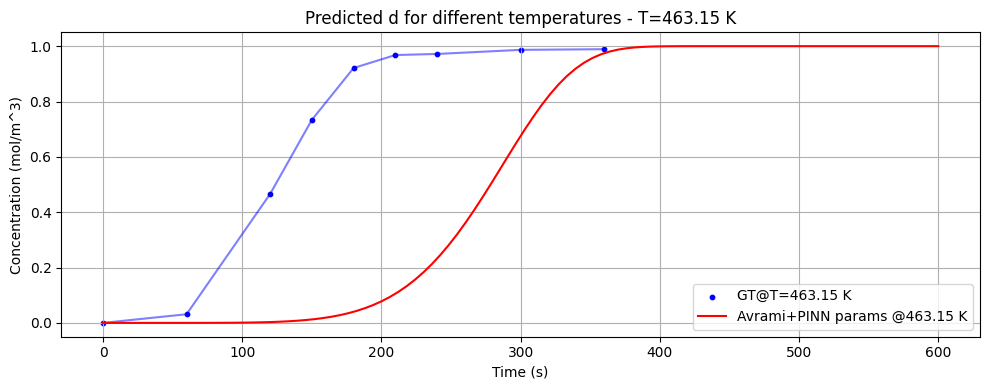

In [ ]:
all_data = get_data()  # dict[int, dict[str, list[float]]]
data_160 = all_data[160]  # 170 degree
data_170 = all_data[170]  # 170 degree  TRAIN
data_180 = all_data[180]  # 170 degree
data_190 = all_data[190]  # 170 degree

predicted_Ea = Ea
predicted_A = B
predicted_n = n
predicted_m = m
print(f"Using predicted values of Ea={predicted_Ea:.2f}, A={predicted_A:.4e}, n={predicted_n:.2f}, m={predicted_m:.4e}")
eq_test = functools.partial(avrami_law, B=predicted_A, Ea=predicted_Ea, m=predicted_m, n=predicted_n, R=R)

times = np.linspace(0, TIME_MAX, 100)

plt.figure(figsize=(10, 4))
for temp in [160, 170, 180, 190]:
    temp_K = temp + 273.15
    expeced_d = eq_test(times, T=temp_K)
    plt.plot(times, expeced_d, label=f"Avrami+PINN params @ T={temp_K} K")

plt.title("Predicted d for different temperatures")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()

# plot all data
for temp, data in zip([160, 170, 180, 190], [data_160, data_170, data_180, data_190]):
    temp_K = temp + 273.15
    plt.figure(figsize=(10, 4))

    c_train_times_X = torch.tensor(data["t"]).reshape(-1, 1)
    c_train_d_Y = torch.tensor(data["C"]).reshape(-1, 1)

    plt.scatter(c_train_times_X.cpu().numpy(), c_train_d_Y.cpu().numpy(), label=f"GT@T={temp_K} K", s=10, color="blue")
    plt.plot(c_train_times_X.cpu().numpy(), c_train_d_Y.cpu().numpy(), alpha=0.5, color="blue")

    if temp == TRAIN_TEMP_CELSIUS:
        c_train_x_scaled = scaler_X.transform(c_train_times_X.reshape(-1, 1)).type(torch.float32)
        d = net.predict(c_train_x_scaled)
        d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
        d = scaler_Y.inverse_transform(d)
        d = d.cpu().numpy()    
        plt.plot(c_train_times_X.cpu().numpy(), d, label=f"PINN@T={temp_K} K", color="orange")

    # plot equation on top of data
    times = np.linspace(0, TIME_MAX, 100)
    eq_d_pred = eq_test(times, T=temp_K)
    plt.plot(times, eq_d_pred, label=f"Avrami+PINN params @{temp_K} K", color="red")
    # plt.scatter(c_train_times_X, eq_test(c_train_times_X.cpu().numpy(), T=temp_K), s=10, color="red")

    plt.title(f"Predicted d for different temperatures - T={temp_K} K")
    plt.xlabel("Time (s)")
    plt.ylabel("Concentration (mol/m^3)")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()
